Install and import libraries

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from astropy import units as u

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (10, 5)

TARGET = "KIC 12069424"
NU_MAX_REFERENCE = 2201.0       
NU_MAX_REFERENCE_ERR = 20.0     
DELTA_NU_REFERENCE = 103.5      
DELTA_NU_REFERENCE_ERR = 0.1    
print("Target:", TARGET)
print("Analysis libraries imported successfully.")

Target: KIC 12069424
Analysis libraries imported successfully.


2. Search the Kepler archive

In [4]:
# Search for all light-curve products for 16 Cygni A without restricting cadence
search_result = lk.search_lightcurve(TARGET, mission="Kepler")
print(search_result)
print("\nNumber of matching products:", len(search_result))

SearchResult containing 4 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr012069424      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr012069424      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr012069424      0.0
  3 Kepler Quarter 05 2010 Kepler    1800 kplr012069424      0.0

Number of matching products: 4


Download observations

In [5]:
if len(search_result) == 0:
    raise RuntimeError(
        "No products were returned. Inspect the archive before continuing."
    )

downloaded = search_result.download_all(flux_column="pdcsap_flux")
if downloaded is None or len(downloaded) == 0:
    raise RuntimeError("The archive search returned products, but downloading them failed.")

print("Downloaded light-curve files:", len(downloaded))
print(downloaded)

Downloaded light-curve files: 4
LightCurveCollection of 4 objects:
    0: <KeplerLightCurve LABEL="KIC 12069424" QUARTER=0 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    1: <KeplerLightCurve LABEL="KIC 12069424" QUARTER=1 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    2: <KeplerLightCurve LABEL="KIC 12069424" QUARTER=2 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    3: <KeplerLightCurve LABEL="KIC 12069424" QUARTER=5 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>


3. Combine and inspect the light curve

Number of valid observations: 10649
Time span (days): 417.62340874705114
Median cadence: 0.0204341632888827 days


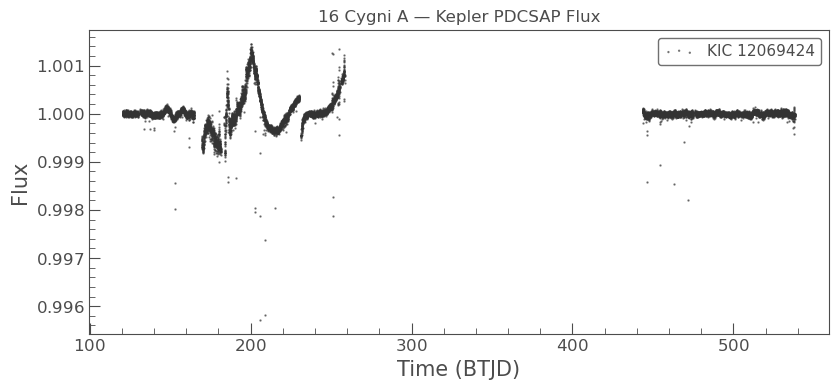

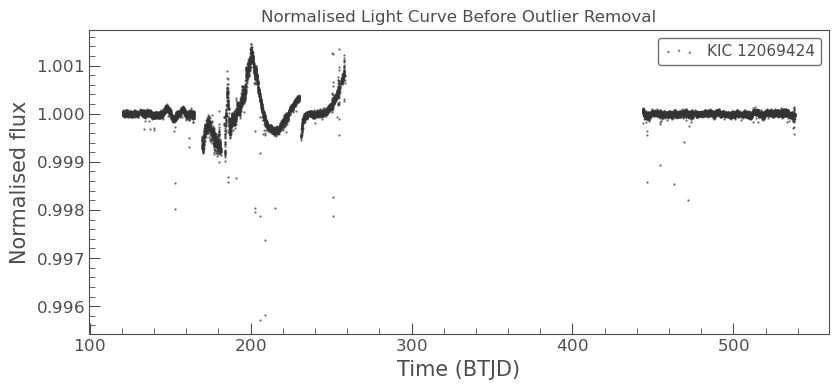

In [6]:
lc_raw = downloaded.stitch().remove_nans()
lc_raw = lc_raw[lc_raw.flux > 0]

if len(lc_raw) < 100:
    raise RuntimeError("Too few valid data points for a meaningful frequency analysis.")

lc = lc_raw.normalize()
print("Number of valid observations:", len(lc))
print("Time span (days):", float((lc.time.max() - lc.time.min()).to_value(u.day)))
print("Median cadence:", np.nanmedian(np.diff(lc.time.value)), "days")

ax = lc_raw.scatter(s=2, alpha=0.6)
ax.set_title("16 Cygni A — Kepler PDCSAP Flux")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Flux")
plt.tight_layout()
plt.show()

ax = lc.scatter(s=2, alpha=0.6)
ax.set_title("Normalised Light Curve Before Outlier Removal")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalised flux")
plt.tight_layout()
plt.show()

4. Remove outliers and inspect processed data

Observations after outlier removal: 10616


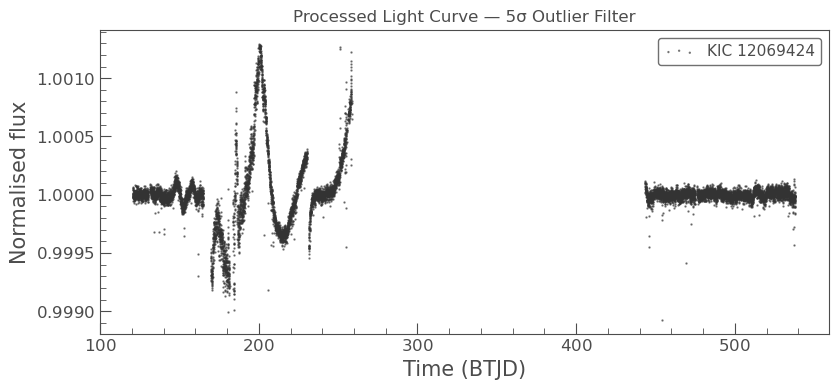

In [7]:
lc_clean = lc.remove_outliers(sigma=5, return_mask=False).remove_nans()
print("Observations after outlier removal:", len(lc_clean))

ax = lc_clean.scatter(s=2, alpha=0.6)
ax.set_title("Processed Light Curve — 5σ Outlier Filter")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalised flux")
plt.tight_layout()
plt.show()

 5. Calculate the power spectrum

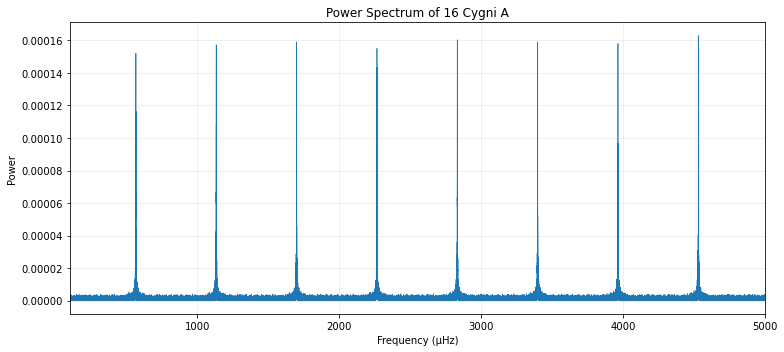

Frequency range (μHz): 100.0 to 5000.0
Number of frequency bins: 884026


In [8]:
periodogram = lc_clean.to_periodogram(
    method="lombscargle",
    minimum_frequency=100 * u.microhertz,
    maximum_frequency=5000 * u.microhertz,
    oversample_factor=5
)

freq_uHz = periodogram.frequency.to_value(u.microhertz)
power = np.asarray(periodogram.power.value, dtype=float)
valid = np.isfinite(freq_uHz) & np.isfinite(power) & (power >= 0)
freq_uHz, power = freq_uHz[valid], power[valid]

if len(freq_uHz) < 100:
    raise RuntimeError("The calculated periodogram has too few valid frequency bins.")

plt.figure(figsize=(11, 5))
plt.plot(freq_uHz, power, linewidth=0.7)
plt.xlabel("Frequency (μHz)")
plt.ylabel("Power")
plt.title("Power Spectrum of 16 Cygni A")
plt.xlim(100, 5000)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Frequency range (μHz):", round(float(freq_uHz.min()), 2), "to", round(float(freq_uHz.max()), 2))
print("Number of frequency bins:", len(freq_uHz))

6. Exploratory estimate of νmax

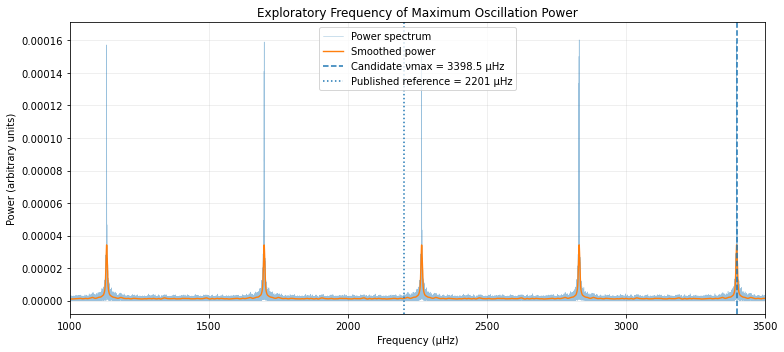

Candidate νmax from smoothed spectrum: 3398.51 μHz
Published reference νmax: 2201.0 ± 20.0 μHz
Difference from reference: 1197.51 μHz


In [9]:
positive_power = np.maximum(power, 0)
smooth_power = gaussian_filter1d(positive_power, sigma=max(1, len(power) / 2500))

nu_region = (freq_uHz >= 1000) & (freq_uHz <= 3500)
if not np.any(nu_region):
    raise RuntimeError("No periodogram samples fall in the selected νmax search region.")

region_indices = np.where(nu_region)[0]
nu_max_index = region_indices[np.argmax(smooth_power[nu_region])]
nu_max_estimate = float(freq_uHz[nu_max_index])

plt.figure(figsize=(11, 5))
plt.plot(freq_uHz, power, linewidth=0.5, alpha=0.45, label="Power spectrum")
plt.plot(freq_uHz, smooth_power, linewidth=1.4, label="Smoothed power")
plt.axvline(nu_max_estimate, linestyle="--", label=f"Candidate νmax = {nu_max_estimate:.1f} μHz")
plt.axvline(NU_MAX_REFERENCE, linestyle=":", label=f"Published reference = {NU_MAX_REFERENCE:.0f} μHz")
plt.xlim(1000, 3500)
plt.xlabel("Frequency (μHz)")
plt.ylabel("Power (arbitrary units)")
plt.title("Exploratory Frequency of Maximum Oscillation Power")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Candidate νmax from smoothed spectrum: {nu_max_estimate:.2f} μHz")
print(f"Published reference νmax: {NU_MAX_REFERENCE:.1f} ± {NU_MAX_REFERENCE_ERR:.1f} μHz")
print(f"Difference from reference: {nu_max_estimate - NU_MAX_REFERENCE:.2f} μHz")

7. Exploratory investigation of Δν

Candidate Δν from local power-spectrum autocorrelation: 100.77 μHz
Published reference Δν: 103.5 ± 0.1 μHz


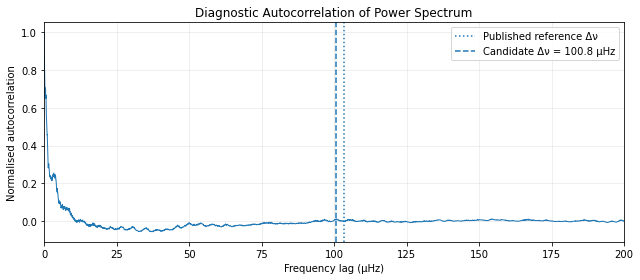

In [10]:
half_width = 700.0
near_envelope = (freq_uHz >= nu_max_estimate - half_width) & (freq_uHz <= nu_max_estimate + half_width)
f_local = freq_uHz[near_envelope]
p_local = power[near_envelope]

delta_nu_estimate = np.nan
lags_uHz = np.array([])
autocorrelation = np.array([])

if len(f_local) >= 50:
    # Interpolate onto a uniform frequency grid before computing autocorrelation.
    df = np.median(np.diff(f_local))
    if np.isfinite(df) and df > 0:
        uniform_f = np.arange(f_local.min(), f_local.max(), df)
        uniform_p = np.interp(uniform_f, f_local, p_local)
        # Remove a smoothed background to emphasise local variations.
        background = gaussian_filter1d(uniform_p, sigma=max(2, len(uniform_p) / 30))
        signal = uniform_p - background
        signal = signal - np.mean(signal)
        ac = np.correlate(signal, signal, mode="full")[len(signal)-1:]
        if ac[0] != 0:
            ac = ac / ac[0]
        lags_uHz = np.arange(len(ac)) * df
        # Search only plausible diagnostic lags; this is not mode identification.
        lag_mask = (lags_uHz >= 50) & (lags_uHz <= 150)
        if np.any(lag_mask):
            candidates = np.where(lag_mask)[0]
            best_lag = candidates[np.argmax(ac[lag_mask])]
            delta_nu_estimate = float(lags_uHz[best_lag])
            autocorrelation = ac

if np.isfinite(delta_nu_estimate):
    print(f"Candidate Δν from local power-spectrum autocorrelation: {delta_nu_estimate:.2f} μHz")
else:
    print("Candidate Δν could not be estimated with this simple procedure.")

print(f"Published reference Δν: {DELTA_NU_REFERENCE:.1f} ± {DELTA_NU_REFERENCE_ERR:.1f} μHz")

if len(autocorrelation):
    plt.figure(figsize=(9, 4))
    plt.plot(lags_uHz, autocorrelation, linewidth=1)
    plt.axvline(DELTA_NU_REFERENCE, linestyle=":", label="Published reference Δν")
    if np.isfinite(delta_nu_estimate):
        plt.axvline(delta_nu_estimate, linestyle="--", label=f"Candidate Δν = {delta_nu_estimate:.1f} μHz")
    plt.xlim(0, 200)
    plt.xlabel("Frequency lag (μHz)")
    plt.ylabel("Normalised autocorrelation")
    plt.title("Diagnostic Autocorrelation of Power Spectrum")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

 8. Compare candidate values with published references

In [11]:
comparison = pd.DataFrame({
    "Parameter": ["νmax (μHz)", "Δν (μHz)"],
    "Notebook candidate": [
        nu_max_estimate,
        delta_nu_estimate if np.isfinite(delta_nu_estimate) else np.nan
    ],
    "Published reference": [NU_MAX_REFERENCE, DELTA_NU_REFERENCE],
    "Published uncertainty": [NU_MAX_REFERENCE_ERR, DELTA_NU_REFERENCE_ERR]
})
comparison["Difference (candidate - reference)"] = (
    comparison["Notebook candidate"] - comparison["Published reference"]
)
display(comparison.round(3))

,Parameter,Notebook candidate,Published reference,Published uncertainty,Difference (candidate - reference)
0,νmax (μHz),3398.509,2201.0,20.0,1197.509
1,Δν (μHz),100.769,103.5,0.1,-2.731


9. Save the processed data and results

In [12]:
light_curve_table = pd.DataFrame({
    "time_BTJD": lc_clean.time.value,
    "normalised_flux": lc_clean.flux.value
})
light_curve_table.to_csv("16_Cygni_A_processed_light_curve.csv", index=False)
comparison.to_csv("16_Cygni_A_parameter_comparison.csv", index=False)
print("Saved: 16_Cygni_A_processed_light_curve.csv")
print("Saved: 16_Cygni_A_parameter_comparison.csv")

Saved: 16_Cygni_A_processed_light_curve.csv
Saved: 16_Cygni_A_parameter_comparison.csv
